In [ ]:
# Connect Google Colab to your Google Drive, so the notebook can reach the assignment
# files. Outside Colab this cell only makes sure the notebook's own folder is importable.
import os
import sys

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

    # EDIT THIS: the folder of this notebook inside your Drive. After mounting, your
    # Drive is at /content/drive/MyDrive (no space), so if you uploaded the assignment
    # to the top level of your Drive, the line below is already correct.
    ASSIGNMENT_DIR = "/content/drive/MyDrive/assignment1/Programming/code"

    if "<" in ASSIGNMENT_DIR or not os.path.isdir(ASSIGNMENT_DIR):
        raise ValueError(
            f"{ASSIGNMENT_DIR} does not exist in your Drive. Set ASSIGNMENT_DIR above to "
            f"the folder holding this notebook, then run this cell again."
        )

    os.chdir(ASSIGNMENT_DIR)
    sys.path.insert(0, ASSIGNMENT_DIR)
else:
    sys.path.insert(0, os.getcwd())

print("Working directory:", os.getcwd())

# Logistic Regression \[13 points\]

**Association:**
Otto-Friedrich University of Bamberg
Chair of Explainable Machine Learning (xAI)
Deep Learning Assignments

**Description:**
This notebook introduces the logistic regression analysis.
Students will learn how to code and apply logistic regression on an image-based 2-class classification problem.

**Author:** Sebastian Doerrich

**Copyright:** Copyright (c) 2022-2026 xAILab Bamberg, Chair of Explainable Machine Learning (xAI), Otto-Friedrich University of Bamberg

**Credits:** Christian Ledig, Sebastian Doerrich

**License:** CC BY-SA

**Version:** 1.0

**Python:** Python 3

**Maintainer:** Sebastian Doerrich

**Email:** sebastian.doerrich@uni-bamberg.de

**Status:** Production

## Context
Welcome to the second part of your first programming assignment.
In this part you will learn how to apply logistic regression on an image-based 2-class classification problem.

## Motivation
In the last exercise we have seen how linear regression can be used to fit a hyperplane (for the 2D case this is a line) to a set of points by minimizing the distances of these points to that hyperplane. This can be used to predict for example the trend in stock, or housing prices based on last observations. However, for other applications, like the separation of two different classes of data points (classification), linear regression can no longer be used to a reasonable extent. Here we rely on another regression model, the so-called logistic regression.
Logistic regression uses the logistic (sigmoid) function to map the output of a linear equation in between the value range \[0, 1\] as it can be seen in the following figure:

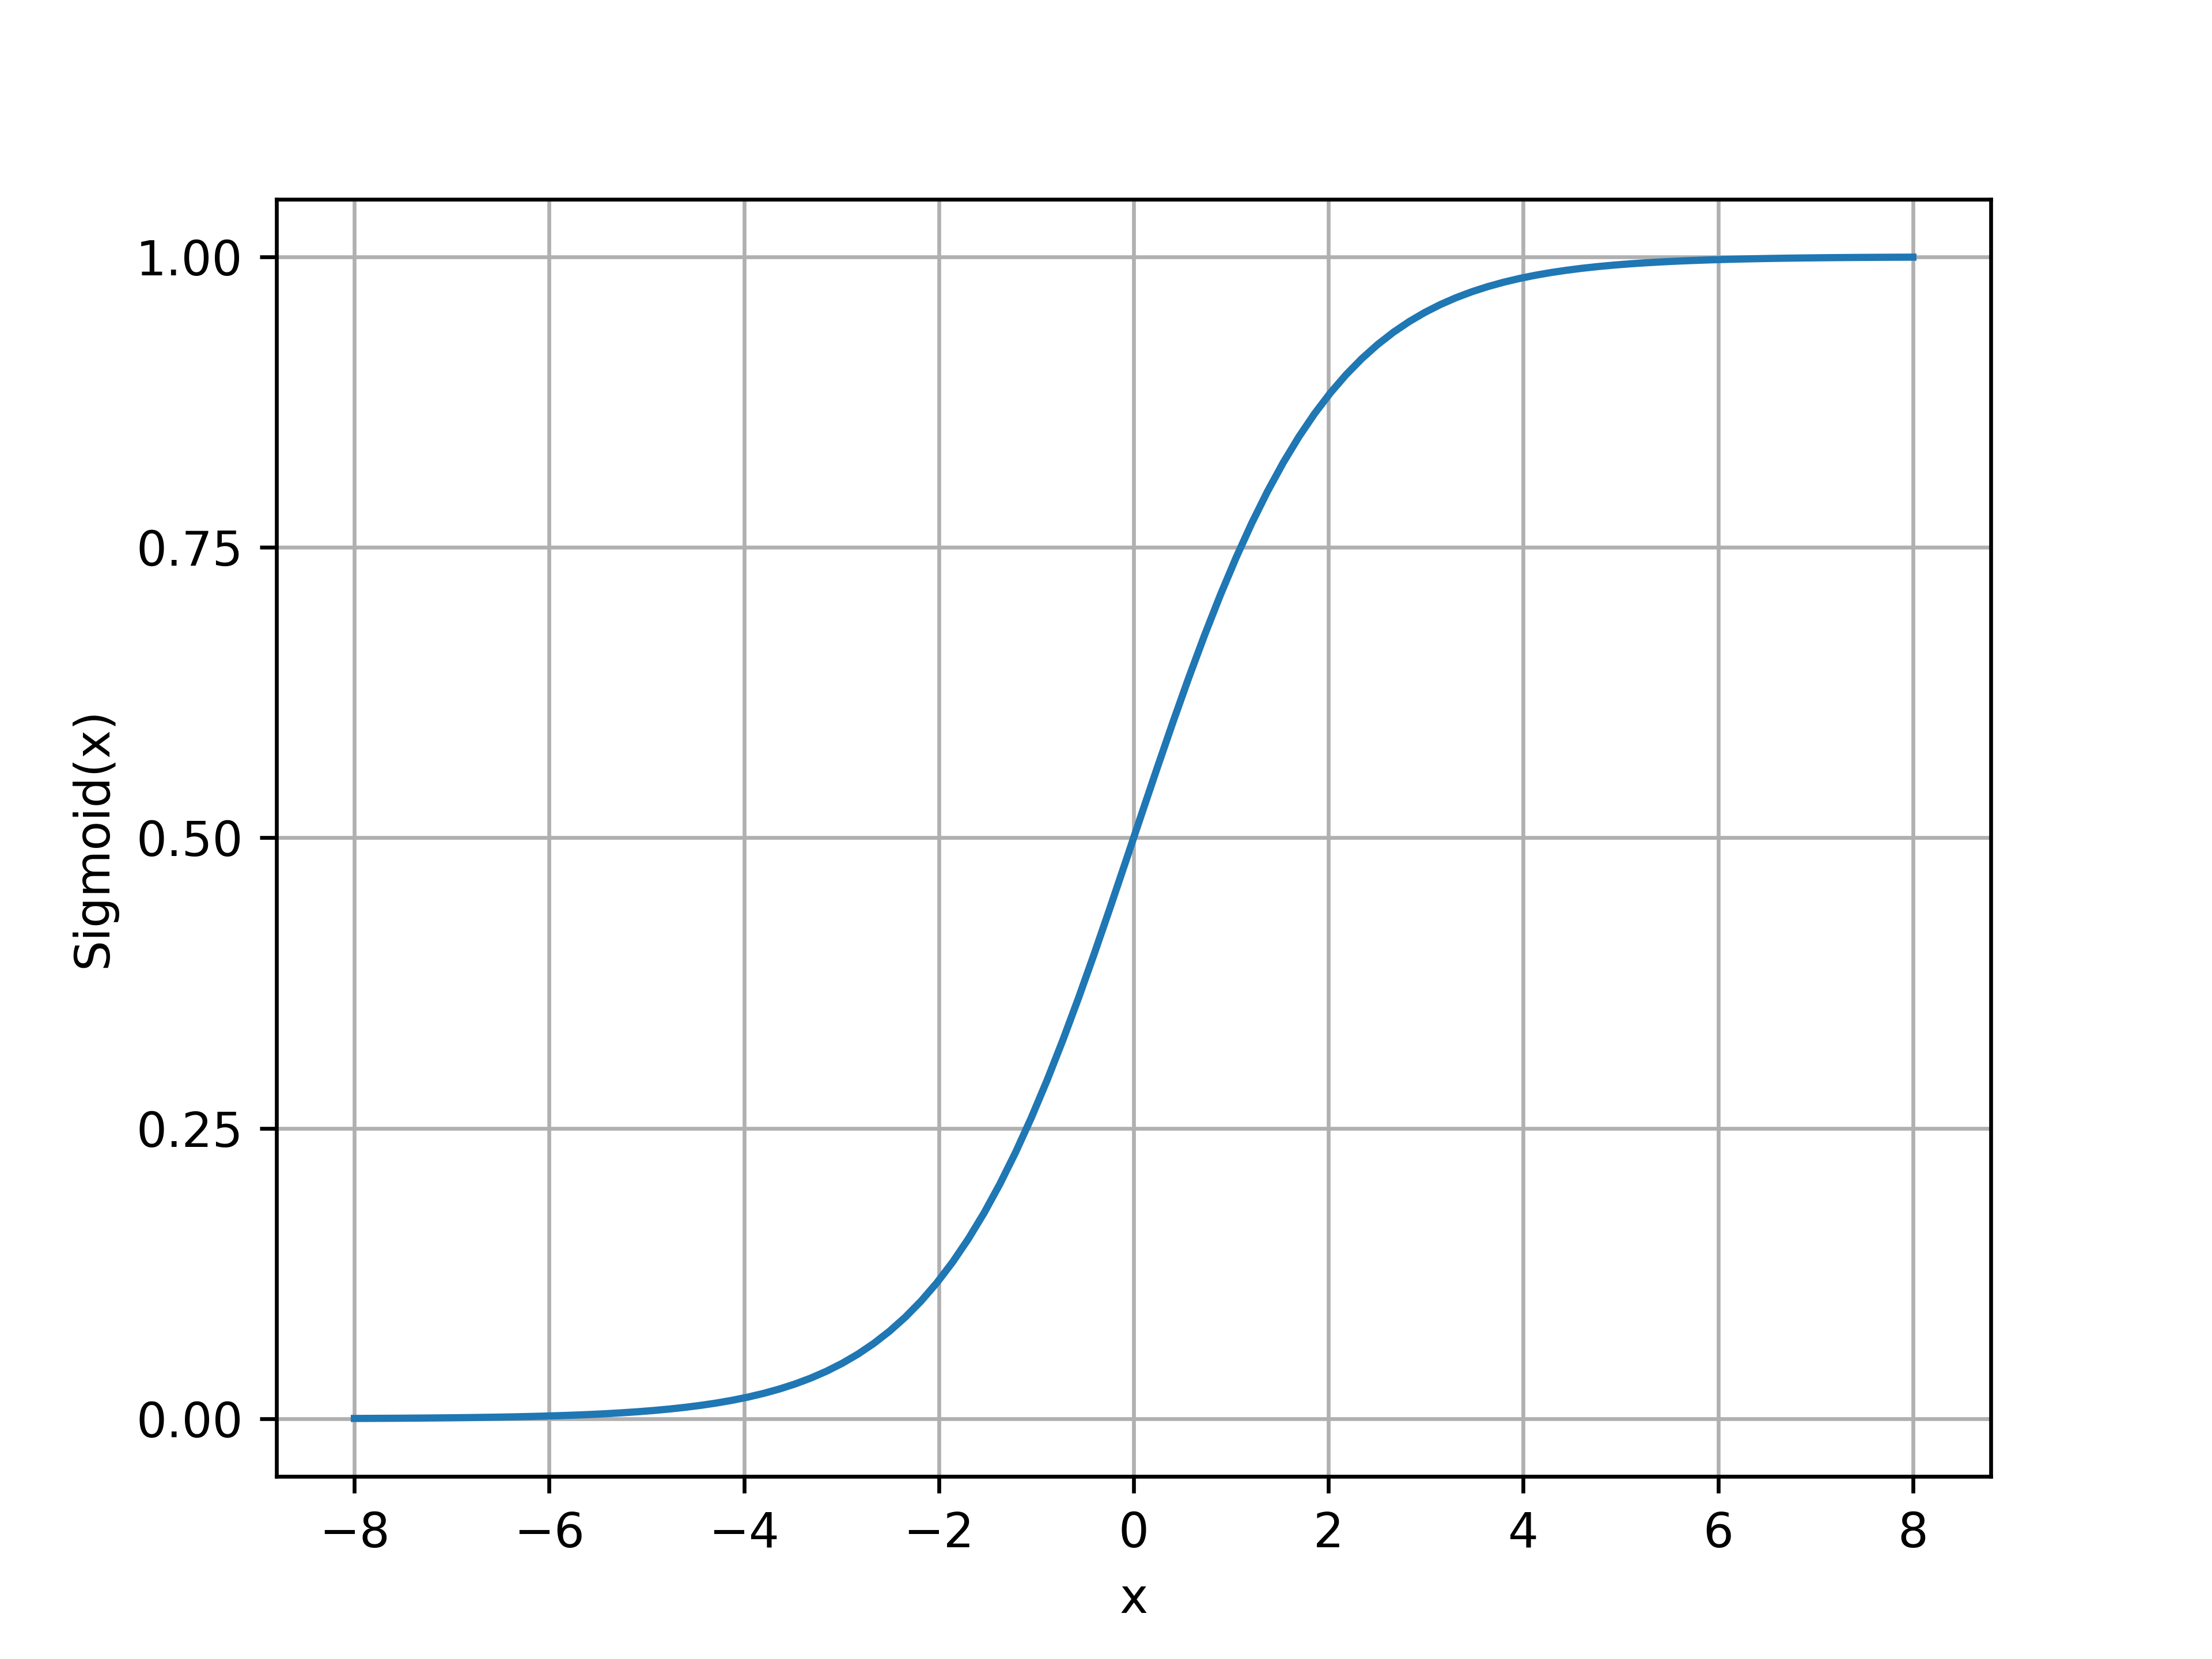

The equation of the sigmoid function is given by:
\begin{equation*}
    \sigma(x) = \frac{1}{1 + {\rm e}^{-x}}
\end{equation*}

These output values between $0$ and $1$ created by the logistic regression algorithm can further be understood as probabilities. This is exactly why logistic regression works well for a 2-class classification problem. The output probabilities can be used to threshold two different classes and assign new samples (data points) to either one class or the other. This fact can be seen in the following figure:

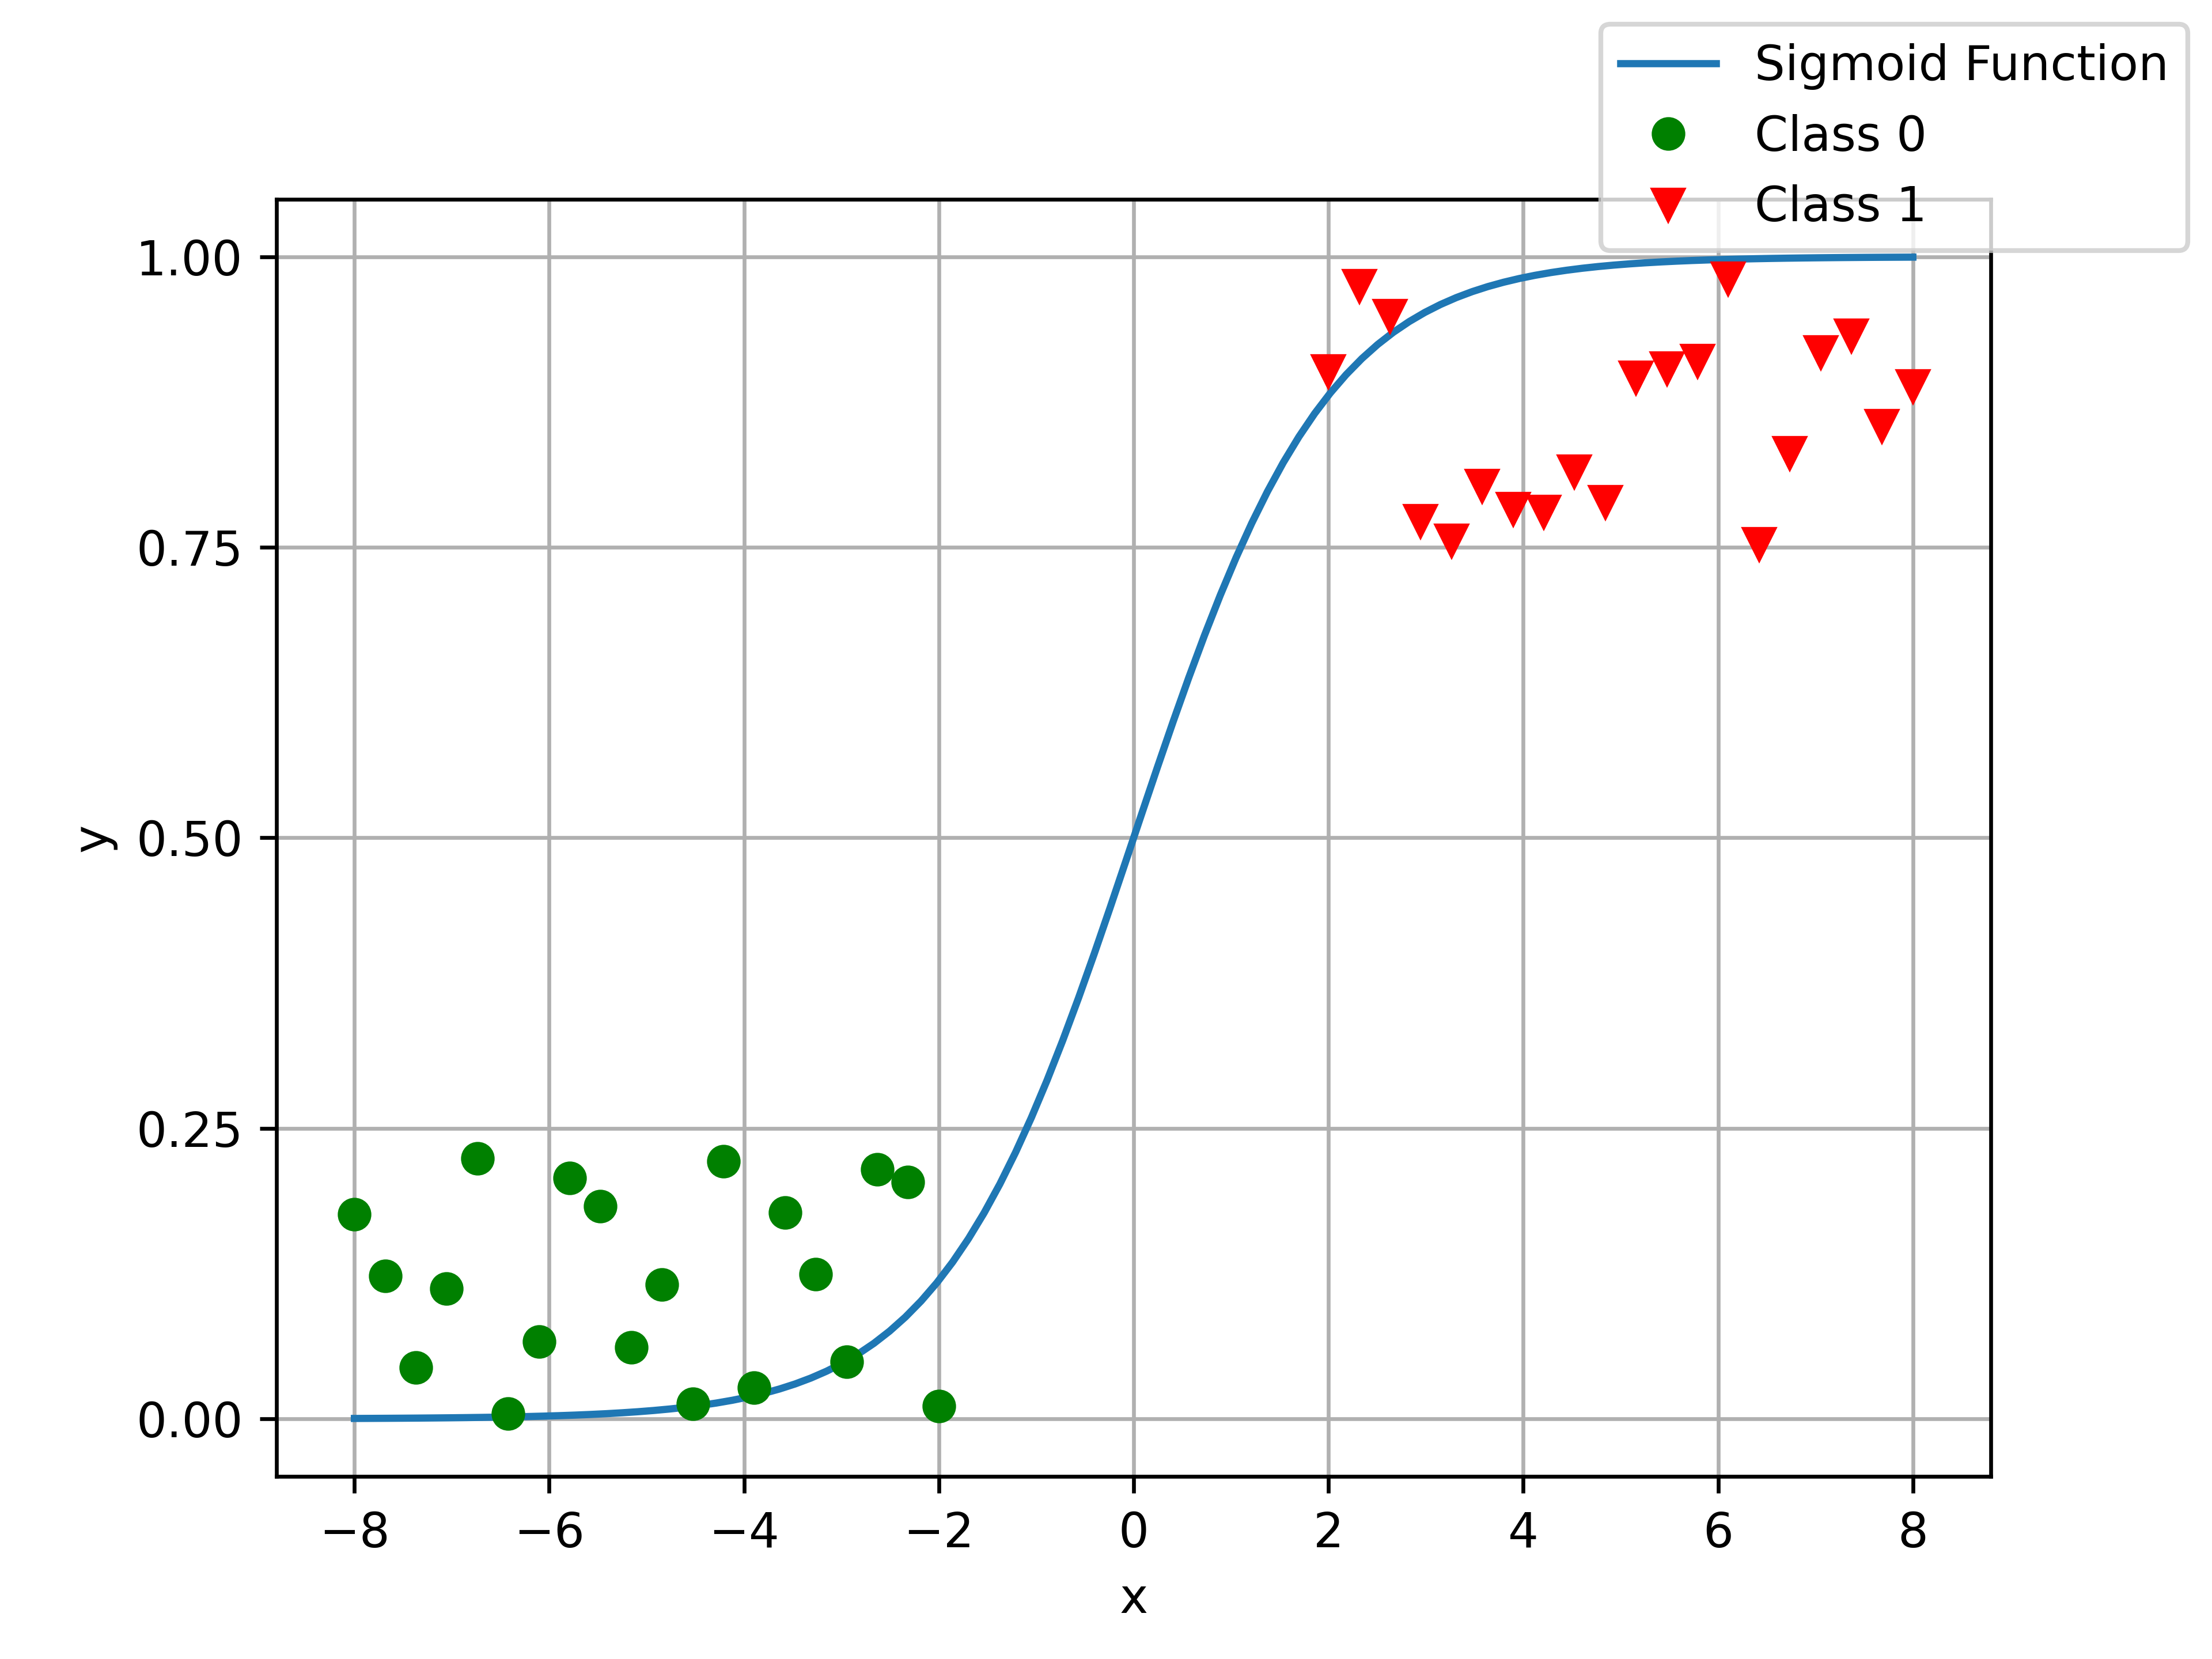

The probabilities for all samples of "Class 0" (green circles) and "Class 1" (red triangles) were calculated using the sigmoid function. We can now use the probability of e.g. $0.5$ to threshold "Class 0" from "Class 1" as well as classify new samples to either one or the other class depending on their probability ($p(\text{new sample})$):
\begin{equation*}
    \text{Class}(\text{new sample}) = \begin{cases} 0 & \text{ if } p(\text{new sample}) < 0.5 \\  1 & \text{ else} \end{cases}
\end{equation*}

Hence, logistic regression represents our very first classification algorithm, and we will implement it in this exercise.

## Instructions
- You will be using Python 3.
- After coding your function, run the cell right below it to check if your result is correct.

## Important Notes for Your Submission
Before submitting your assignment, please make sure you are not doing the following:

1. You have not added any _extra_ `print` statement(s) in the assignment.
2. You have not added any _extra_ code cell(s) in the assignment.
3. You have not changed any of the function parameters.
4. You are not using any global variables inside your graded exercises. Unless specifically instructed to do so, please refrain from it and use the local variables instead.
5. You are not changing the assignment code where it is not required, like creating _extra_ variables.

If you do any of the mentioned, our test scripts will fail and as a result you will receive **0 points** for the respective task.

<a name='0'></a>
## 0 - Import the Necessary Libraries \[0 point\] ##

In [ ]:
# Import packages
import numpy as np
from PIL import Image
from pathlib import Path
from skimage.transform import resize
import random
import pickle
import copy

import matplotlib.pyplot as plt
%matplotlib inline

<a name='1'></a>
## 1 - Data Loading \[3 points\] ##

The first task of this exercise is to load the dataset.

> **TODO:**
> 1. Implement the class `DataLoader`.
> 2. Implement the constructor `__init__` which initializes our data loader.
> 3. Implement the method `load_images` which loads all cat and dog images and convert them to numpy arrays.
> 4. Implement the method `initialize_classes` which initializes the classes as a dictionary.
> 5. Implement the method `initialize_labels` which initializes the labels for our two classes cats and dogs.
> 6. Implement the method `split_images_and_labels_into_train_and_test_sets` which splits all images and their corresponding labels into a training and test set.
> 7. Implement the method `load_train_and_test_sets` which runs all previous functions to create the training and test sets.
> 8. Implement the method `get_train_and_test_sets` which returns the train and test sets.


In [ ]:
class DataLoader:
    """
    This class creates a data loader instance.
    """

    def __init__(self, file_path_cat_img: str, file_path_dog_img: str, cat_label: int, dog_label: int, train_split_ratio: float):
        """
        Constructor.

        :param file_path_cat_img: Path to the folder containing the cat images.
        :param file_path_dog_img: Path to the folder containing the dog images.
        :param cat_label: Label for all cat instances.
        :param dog_label: Label for all dog instances.
        :param train_split_ratio: Float containing the split ratio for the training data (ratio inbetween [0.0, 1.0]).
        """

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Store the given parameters in class variables                       #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        self.classes = {}
        self.train_images = None
        self.train_labels = None
        self.test_images = None
        self.test_labels = None


    @staticmethod
    def load_images(file_path_cat_img: str, file_path_dog_img: str):
        """
        Load all cat and dog images and convert them to numpy arrays.

        :return: List of all cat images converted to numpy arrays, list of all dog images converted to numpy arrays.
        """

        cat_images = None
        dog_images = None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Get the paths to all images, sorted by file name (sorted()), so     #
        #       that every computer loads them in the same order.                   #
        #    2) Load each image into a numpy array and store all cat arrays as well #
        #       as dog arrays together in a separate list.                          #
        #       Checkout Image.open from PIL for how to load an image.              #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return cat_images, dog_images

    @staticmethod
    def initialize_classes(cat_label: int, dog_label: int):
        """
        Initialize the classes as a dictionary.

        :param cat_label: Label for the cat images given as an int.
        :param dog_label: Label for the dog images given as an int.

        :return: Dictionary containing the labels as keys and the strings 'cat' and 'dog' as values.
        """

        classes = None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Initialize the classes as a dictionary containing the labels as     #
        #       keys and the strings 'cat' and 'dog' as values.                     #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return classes


    @staticmethod
    def initialize_labels(cat_images: list, dog_images: list, cat_label: int, dog_label: int):
        """
        Initialize the labels for our two classes.

        :param cat_images: List containing all cat images as np.arrays.
        :param dog_images: List containing all dog images as np.arrays.
        :param cat_label: Label for the cat images given as an int.
        :param dog_label: Label for the dog images given as an int.

        :return: List of the same length as cat_images containing only the label for cat, List of the same length as dog_images containing only the label for dog.
        """

        cat_labels = None
        dog_labels = None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Initialize a list that has the same length as cat_images and        #
        #       contains only the value cat_label.                                  #
        #    2) Initialize a list that has the same length as dog_images and        #
        #       contains only the value dog_label.                                  #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return cat_labels, dog_labels


    @staticmethod
    def split_images_and_labels_into_train_and_test_sets(cat_images: list, dog_images: list, cat_labels: list, dog_labels: list, train_split_ratio: float,
                                                         seed=1337):
        """
        Split all images and their corresponding labels into a training and test set.

        :param cat_images: List containing all cat images as np.arrays.
        :param dog_images: List containing all dog images as np.arrays.
        :param cat_labels: List of same length as cat_images containing the cat label.
        :param dog_labels: List of same length as dog_images containing the dog label.
        :param train_split_ratio: Float containing the split ratio for the training data (ratio inbetween [0.0, 1.0]).
        :param seed: Ensure that your random operations will always work the same way.

        :return: Training set, Test set
        """

        train_images, train_labels, test_images, test_labels = None, None, None, None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Concatenate the cat and dog image lists together.                   #
        #    2) Concatenate the cat and dog label lists together.                   #
        #    3) Shuffle the both lists the same way, to mix the images and labels   #
        #       amongst each other.                                                 #
        #       Checkout random.seed and random.shuffle for that purpose.           #
        #    4) Split the image list and the label list into a train and test set   #
        #       based on train_split_ratio.                                         #
        #       I.e. if train_split_ratio is 0.8 assign the first 80% of images to  #
        #       the train set and the last 20% to the test set. Same for the labels #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return train_images, train_labels, test_images, test_labels


    def load_train_and_test_sets(self):
        """
        Load the images, generate corresponding labels and split them into train and test sets.
        """

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Load the cat and dog images into np.arrays.                         #
        #    2) Initialize the classes dictionary and store in a class variable     #
        #    3) Initialize the labels                                               #
        #    4) Create the train and test sets and store them in class variables    #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

    def get_train_and_test_sets(self):
        """
        Get the train and test sets.

        :return: training images, training labels, test images, test labels
        """

        train_images, train_labels, test_images, test_labels = None, None, None, None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Extract the training images, training labels, test images and test  #
        #       labels from the class instance                                      #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return train_images, train_labels, test_images, test_labels

In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestDataLoader

In [ ]:
# Show your results

# Initialize the hyperparameters
idx = 25

# Load the parameters
file_path_parameters = "../data/logistic_regression.pkl"

with open(file_path_parameters, 'rb') as f:
    p = pickle.load(f)

# Initialize the data loader
data_loader = DataLoader(p['file_path_cat_img'], p['file_path_dog_img'], p['cat_label'], p['dog_label'], p['train_split_ratio'])
data_loader.load_train_and_test_sets()

# Extract the train set
train_images, train_labels, test_images, _ = data_loader.get_train_and_test_sets()

print('Number of training images: ', len(train_images))
print('Number of test images: ', len(test_images))

# Show an example of the train set
plt.imshow(train_images[idx])
print ("The label is " + str(train_labels[idx]) + ", hence it is a '" + data_loader.classes[train_labels[idx]] +  "' picture.")

<a name='2'></a>
## 2 - Preprocessing \[2 points\] ##

The second task of this exercise is to preprocess the dataset.
Preprocessing can include:
- Resizing the inputs, so that their dimensions match
- Reshaping the inputs, so that calculations can be performed more efficiently
- Cropping the inputs, so that unnecessary information is deleted or the data dimensionality is reduced (enable computations)
- Centering/Standardizing/Normalizing the inputs
- ...

You will implement some of these methods in the code block below.

> **TODO:**
> 1. Implement the class `Preprocessor`.
> 2. Implement the method `resize_images` which resizes all images from their original shape to a new shape.
> 3. Implement the method `reshape_sets` which reshapes the sets from lists to np.arrays.
> 4. Implement the method `flatten_images` which flattens the train and test images over the spatial dimension.
> 5. Implement the method `normalize_images` which normalizes the train and test image sets.
> 6. Implement the method `preprocess` which runs all previous functions to preprocess the training and test sets.


In [ ]:
class Preprocessor:
    """
    This class creates a preprocessor instance.
    """

    @staticmethod
    def resize_images(train_images: list, test_images: list, new_shape=(64, 64, 3)):
        """
        Resize all images from their original shape to the shape new_shape.

        :param train_images: List containing all train images as np.arrays with the shape (m, n, 3).
        :param test_images: List containing all test images as np.arrays with the shape (m, n, 3).
        :param new_shape: New shape given as a tuple (num_px, num_px, 3).

        :return: List containing all resized train images, List containing all resized test images
        """

        resized_train_images = None
        resized_test_images = None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Resize all images from their original shape to shape (64, 64, 3).   #
        #       You might want to check out the resize function of                  #
        #       skimage.transform for that. Pass preserve_range=True: by            #
        #       default, resize also rescales uint8 pixels to [0, 1], and           #
        #       normalize_images() below expects values in [0, 255].                #
        #    2) Return the resized images as lists.                                 #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return resized_train_images, resized_test_images

    @staticmethod
    def reshape_sets(train_images: list, test_images: list, train_labels: list, test_labels: list):
        """
        Reshape the train and test image sets from a list of the form [image1, image2, ...] to an np.array of shape (num_images, num_px, num_px, 3).
        Reshape the train and test label sets from a list of the form [label1, label2, ...] to an np.array of shape (1, num_labels).

        :param train_images: List containing all train images as np.arrays with the shape (num_px, num_px, 3).
        :param test_images: List containing all test images as np.arrays with the shape (num_px, num_px, 3).
        :param train_labels: List containing all train labels.
        :param test_labels: List containing all test labels.

        :return: Reshaped train image set as a np.array of shape (num_images, num_px, num_px, 3),
                 reshaped test image set as a np.array of shape (num_images, num_px, num_px, 3),
                 reshaped train label set as a np.array of shape (1, num_labels), reshaped test label set as a np.array of shape (1, num_labels)
        """

        reshaped_train_images = None
        reshaped_test_images = None
        reshaped_train_labels = None
        reshaped_test_labels = None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Reshape the train and test image sets from a list of the form       #
        #       [image1, image2, ...] to an np.array of shape                       #
        #       (num_images, num_px, num_px, 3).                                    #
        #    2) Reshape the train and test label sets from a list of the form       #
        #       [label1, label2, ...] to an np.array of shape                       #
        #       (1, num_labels).                                                    #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return reshaped_train_images, reshaped_test_images, reshaped_train_labels, reshaped_test_labels

    @staticmethod
    def flatten_images(train_images: np.array, test_images: np.array):
        """
        Flatten the train and test images from the shape (num_images, num_px, num_px, 3) to the shape (num_px * num_px * 3, num_images).

        :param train_images: np.array containing all train images of shape (num_images, num_px, num_px, 3).
        :param test_images: np.array containing all test images of shape (num_images, num_px, num_px, 3).

        :return: Flattened train image array of shape (num_px * num_px * 3, num_images), Flattened test image array of shape (num_px * num_px * 3, num_images).
        """

        flattened_train_images = None
        flattened_test_images = None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Flatten the train image array from the shape (num_images, num_px,   #
        #       num_px, 3) to the shape (num_px * num_px * 3, num_images).          #
        #    2) Flatten the test image array from the shape (num_images, num_px,    #
        #       num_px, 3) to the shape (num_px * num_px * 3, num_images).          #
        #                                                                           #
        #    Hint: Reshape the arrays first to shape                                #
        #          (num_images, num_px * num_px * 3) and transpose them afterwards  #
        #          to obtain the final shape.                                       #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return flattened_train_images, flattened_test_images

    @staticmethod
    def normalize_images(train_images: np.array, test_images: np.array):
        """
        Normalize the train and test image sets by dividing every row of the dataset by 255 which is the maximum value of a pixel channel.

        :param train_images: np.array containing all train images of shape (num_px * num_px * 3, num_images).
        :param test_images: np.array containing all test images of shape (num_px * num_px * 3, num_images).

        :return: Normalized train image array, Normalized test image array
        """

        normalized_train_images = None
        normalized_test_images = None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Normalize the train image set by dividing every row of the dataset  #
        #       by 255.                                                             #
        #    2) Normalize the train image set by dividing every row of the dataset  #
        #       by 255.                                                             #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return normalized_train_images, normalized_test_images

    @staticmethod
    def preprocess(train_images: list, test_images: list, train_labels: list, test_labels: list, new_shape=(64, 64, 3)):
        """
        Preprocess the data set.

        :param train_images: List containing all train images as np.arrays with the shape (num_px, num_px, 3).
        :param test_images: List containing all test images as np.arrays with the shape (num_px, num_px, 3).
        :param train_labels: List containing all train labels.
        :param test_labels: List containing all test labels.
        :param new_shape: New shape given as a tuple (num_px, num_px, 3).

        :return: Preprocessed train images, preprocessed test images, preprocessed train labels, preprocessed test labels
        """

        preprocessed_train_images = None
        preprocessed_test_images = None
        preprocessed_train_labels = None
        preprocessed_test_labels = None

        #############################################################################
        #                            START OF YOUR CODE                             #
        # TODO:                                                                     #
        #    1) Resize all images from their original shape to the shape 'new_shape'#
        #    2) Reshape the train and test image sets from a lists to np.arrays.    #
        #       Reshape the train and test label sets from a lists to np.arrays.    #
        #    3) Flatten the train and test images.                                  #
        #    4) Normalize the train and test image sets.                            #
        #############################################################################


        #############################################################################
        #                              END OF YOUR CODE                             #
        #############################################################################

        return preprocessed_train_images, preprocessed_test_images, preprocessed_train_labels, preprocessed_test_labels


In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestPreprocessor

<a name='3'></a>
## 3 - Building the Algorithm \[7 points\] ##

The third task of this exercise is to build the individual parts of our algorithm.
For that you will build a Logistic Regression, using a Neural Network mindset. The following figure shows why the Logistic Regression algorithm is indeed a very simple Neural Network.

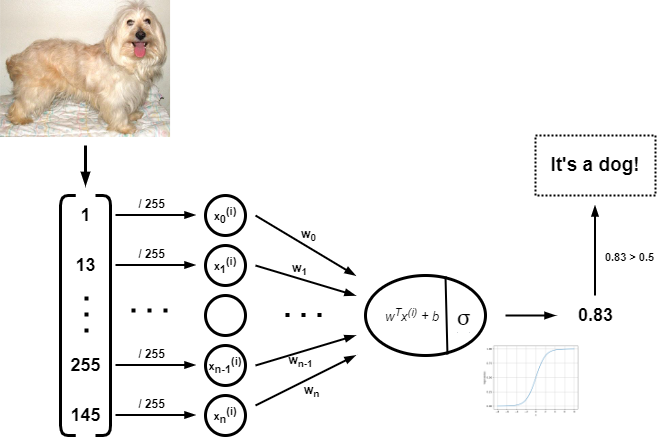

Underlying math of the algorithm for one sample $x^{(i)}$:
\begin{equation}
    z^{(i)} = w^{T}x^{(i)} + b
\end{equation}
\begin{equation}
    \hat{y}^{(i)} = a^{(i)} = sigmoid(z^{(i)})
\end{equation}
\begin{equation}
    \mathcal{L}(a^{(i)}, y^{(i)}) = -y^{(i)} \text{log}(a^{(i)}) - (1 - y^{(i)}) \text{log}(1 - a^{(i)})\\
\end{equation}

And the cost is then computed by summing over all training samples $m$ like this:
\begin{equation}
    J = \frac{1}{m} \sum_{i=1}^{m} \mathcal{L}(a^{(i)}, y^{(i)})
\end{equation}

<a name='3-1'></a>
### 3.1 - Activation Function \[1 point\] ###

For the first part of our algorithm, we will implement the activation function, which will be the sigmoid function.
Remember the sigmoid function can be compted like this:
\begin{equation}
    \sigma(x) = \frac{1}{1 + e^{-x}}
\end{equation}

> **TODO:**
> 1. Implement the method `sigmoid` which calculates the sigmoid activation function for an input `x`.


In [ ]:
def sigmoid(x: np.ndarray):
    """
    Sigmoid activation function.

    :param x: Input given as float or np.ndarray.

    :return: Result of sigmoid function for given input x.
    """

    s = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Implement the sigmoid activation function.                          #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return s

In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestActivation

<a name='3-2'></a>
### 3.2 - Parameter Initialization \[0.75 point\] ###

In the next step we will initialize our "network" parameters.
For simplicity reasons we will use zero initialization here. However, be advised that this is normally no ideal solution.

> **TODO:**
> 1. Implement the method `initialize_with_zeros` which initializes the weights of the network "w" as a vector of zeros and the bias "b" as 0.


In [ ]:
def initialize_with_zeros(dim: int):
    """
    This function initializes the weights of the network "w" as a vector of zeros of shape (dim, 1) and the bias "b" as 0.

    :param dim: row-dimension of the weights.

    :return: Weights "w" of the network, bias "b" of the network
    """

    w = None
    b = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Initialize the weights of the network "w" as a vector of zeros of   #
    #       shape (dim, 1).                                                     #
    #    2) Initialize the bias of the network "b" as 0 (float).                #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return w, b

In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestInitialization

<a name='3-3'></a>
### 3.3 - Forward and Backward Propagation \[1 point\] ###

Now that your parameters are initialized, we can do the "forward" and "backward" propagation steps for learning the parameters.

Forward propagation (Compute the cost for the current input based on the current parameters):
- You get the input $X$
- You compute $A = \sigma(w^T X + b) = (a^{(1)}, a^{(2)}, ..., a^{(m-1)}, a^{(m)})$
- You calculate the cost function: $J = -\frac{1}{m}\sum_{i=1}^{m}(y^{(i)}\log(a^{(i)})+(1-y^{(i)})\log(1-a^{(i)}))$

Backward propagation (Calculate the gradients of the parameters based on the current input):
- $\frac{\partial J}{\partial w} = \frac{1}{m}X(A-Y)^T$
- $\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (a^{(i)}-y^{(i)})$


> **TODO:**
> 1. Implement the method `forward` which calculates the forward propagation of our model.
> 2. Implement the method `backward` which calculates the backward propagation of our model.


In [ ]:
def forward(X: np.ndarray, Y: np.ndarray, w: np.ndarray, b: float):
    """
    Calculate the forward propagation of our model.

    :param X: Input of size (num_px * num_px * 3, number of samples).
    :param Y: True "label" vector (containing 0 if cat, 1 if dog) of size (1, number of samples).
    :param w: Weights given as a numpy array of size (num_px * num_px * 3, 1).
    :param b: Bias given as a scalar.

    :return: Activated input, current cost
    """

    A = None
    cost = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Calculate the activated input "A".                                  #
    #    2) Calculate the cost for the current input and parameters.            #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    cost = np.squeeze(np.array(cost))

    return A, cost

In [ ]:
def backward(X: np.ndarray, Y: np.ndarray, A: np.ndarray):
    """
    Calculate the backward propagation of our model.

    :param X: Input of size (num_px * num_px * 3, number of samples).
    :param Y: True "label" vector (containing 0 if cat, 1 if dog) of size (1, number of samples).
    :param A: Activated input X.

    :return: The gradient of the cost with respect to "w" as well as the gradient of the cost with respect to "b" stored in a dictionary.
    """

    grads = {"dw": None, "db": None}

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Calculate the gradient of the cost with respect to "w".             #
    #    2) Calculate the gradient of the cost with respect to "b".             #
    #    3) Store the gradients in the dictionary "grads".                      #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return grads

In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestForwardAndBackward

<a name='3-4'></a>
### 3.4 - Optimization \[0.5 point\] ###

So far, we initialized our parameters, computed the cost as well as the gradients of our cost with respect to our parameters.
Now we need to optimize the latter to ensure that our model performs better and better over time.
For that we will update the parameters using gradient descent.

The goal is to learn $w$ and $b$ by minimizing the cost function $J$.
We know that the update rule of gradient descent for a parameter $\theta^{(t)}$ is defined as:
\begin{equation}
    \theta^{(t+1)} = \theta^{(t)} - \textit{lr} * \frac{\partial J}{\partial \theta^{(t)}}
\end{equation}
where $\textit{lr}$ is the learning rate.

> **TODO:**
> 1. Implement the method `optimize` which optimizes 'w' and 'b' by running the gradient descent algorithm.


In [ ]:
def optimize(w: np.ndarray, b: float, grads: dict, learning_rate=0.5):
    """
    Optimize 'w' and 'b' by running the gradient descent algorithm.

    :param w: Weights given as a numpy array of size (num_px * num_px * 3, 1).
    :param b: Bias given as a scalar.
    :param grads: Dictionary containing the gradients of the cost function with respect to the weights and the bias.
    :param learning_rate: Learning rate of the gradient descent update rule.

    :return: The gradient of the cost with respect to "w" as well as the gradient of the cost with respect to "b" stored in a dictionary.
    """

    params = {"w": None, "b": None}

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Read out the gradient dictionary.                                   #
    #    2) Run the gradient descent algorithm to update the parameters.        #
    #    3) Store the updated parameters in the dictionary "params".            #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return params

In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestOptimization

<a name='3-5'></a>
### 3.5 - Prediction \[0.75 point\] ###

The last part will ensure that our model keeps improving over time. But so far we are not able to see any results of that. Our model is not doing anything yet. Hence, in this part we will implement the prediction of the model. In our case, we want that our model predicts either a cat or a dog for a given image.

> **TODO:**
> 1. Implement the method `predict` which predicts whether the label is 0 or 1 using the learned logistic regression parameters (w, b).


In [ ]:
def predict(X: np.ndarray, w: np.ndarray, b: float):
    """
    Predict whether the label is 0 or 1 using the learned logistic regression parameters (w, b).

    :param X: Input of size (num_px * num_px * 3, number of samples).
    :param w: Weights given as a numpy array of size (num_px * num_px * 3, 1).
    :param b: Bias given as a scalar.

    :return: The predictions as a numpy array of shape (1, m) containing all predictions (0/1) for the samples m in X.
    """

    Y_pred = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Initialize the predictions as a zero array with the correct shape.  #
    #    2) Calculate the activations "A" of the input which represents the     #
    #       predicted probabilities of a cat or dog being present in the        #
    #       picture (You may want to reshape "w" before).                       #
    #    3) Convert the probabilities to actual predictions of either 0 or 1.   #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    return Y_pred

In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestPrediction

<a name='3-6'></a>
### 3.6 - Merge all Functions into a Model \[3 points\] ###

We have implemented all individual parts of our algorithm. The last step that is missing is to merge all of these functions into an executable model.

> **TODO:**
> 1. Implement the method `model` which creates the logistic regression model.


In [ ]:
def model(X_train: np.ndarray, Y_train: np.ndarray, X_test: np.ndarray, Y_test: np.ndarray, num_iterations=2000, learning_rate=0.5, print_cost=False):
    """
    Create the logistic regression model.

    :param X_train: Training set represented by a numpy array of shape (num_px * num_px * 3, m_train).
    :param Y_train: Training labels represented by a numpy array (vector) of shape (1, m_train).
    :param X_test: Test set represented by a numpy array of shape (num_px * num_px * 3, m_test).
    :param Y_test: Test labels represented by a numpy array (vector) of shape (1, m_test).
    :param num_iterations: Hyperparameter representing the number of iterations to optimize the parameters.
    :param learning_rate: Hyperparameter representing the learning rate used in the update rule of optimize().
    :param print_cost: Set to True to print the cost every 100 iterations.

    :return: Dictionary containing information about the model.
    """

    costs = []

    model_output = {"costs": None,
                    "Y_pred_test": None, "Y_pred_train" : None,
                    "w" : None, "b" : None,
                    "learning_rate" : None, "num_iterations": None}

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Initialize the parameters with zeros.                               #
    #    2) Train the model by running the forward, the backward and the        #
    #       optimization step for 'num_iterations'-times                        #
    #       - Please take care to update the parameters w and b for each new    #
    #         iteration                                                         #
    #       - Store the calculated cost for the first iteration and then for    #
    #         each 100-iterations in the variable 'costs', so we can track the  #
    #         development                                                       #
    #    3) Run the prediction for the training and test set samples.           #
    #    4) Fill the output dictionary with the respective values.              #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################
    # Print train/test Errors
    if print_cost:
        for i in range(len(costs)):
            print ("Cost after iteration %i: %f" %((i * 100), costs[i]))

        print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_pred_train - Y_train)) * 100))
        print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_pred_test - Y_test)) * 100))

    return model_output

In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestModel


## 4 - Viewing and Evaluate the Results \[1 point\] ##

If you successfully pass all the tests before, let's have a look at our results.

> **TODO:**
> 1. Implement the method `evaluate` which puts everything together: it loads the dataset, preprocesses it, trains the model and creates predictions for the unseen test images.


In [ ]:
def evaluate(file_path_cat_img: str, file_path_dog_img: str, cat_label: int, dog_label: int, train_split_ratio: float, new_shape: tuple, num_iterations: int,
             learning_rate: float, print_cost: bool):
    """
    This functions puts everything together.
        1. Load the dataset.
        2. Preprocess the dataset.
        3. Train the model and create predictions.
        4. Show the results.

    :param file_path_cat_img: Path to the folder containing the cat images.
    :param file_path_dog_img: Path to the folder containing the dog images.
    :param cat_label: Label for all cat instances.
    :param dog_label: Label for all dog instances.
    :param train_split_ratio: Float containing the split ratio for the training data (ratio inbetween [0.0, 1.0]).
    :param new_shape: New shape for resizing each image given as a tuple (num_px, num_px, 3).
    :param num_iterations: Hyperparameter representing the number of iterations to optimize the parameters.
    :param learning_rate: Hyperparameter representing the learning rate used in the update rule of optimize().
    :param print_cost: Set to True to print the cost every 100 iterations.
    """

    X_train, X_test, Y_train, Y_test = None, None, None, None
    logistic_regression_model = None

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    1) Load the dataset and split it to train and test sets.               #
    #    2) Run the preprocessing and update the variables X_train, X_test,     #
    #       Y_train, Y_test accordingly.                                        #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    print('Number of training images: ', str(X_train.shape[1]))
    print('Number of test images: ', str(X_test.shape[1]))
    print ("Before flattening each image was of size: (" + str(new_shape[0]) + ", " + str(new_shape[0]) + ", 3)")
    print ("After flattening each image is now of size: (" + str(new_shape[0] * new_shape[0] * 3) + ", 1)")
    print ("train_set_x shape: " + str(X_train.shape))
    print ("train_set_y shape: " + str(Y_train.shape))
    print ("test_set_x shape: " + str(X_test.shape))
    print ("test_set_y shape: " + str(Y_test.shape))

    #############################################################################
    #                            START OF YOUR CODE                             #
    # TODO:                                                                     #
    #    3) Train the model, print the cost and execute the prediction.         #
    #############################################################################


    #############################################################################
    #                              END OF YOUR CODE                             #
    #############################################################################

    print("Model output: \n")

    for key in logistic_regression_model.keys():
        print(key, ": ", logistic_regression_model[key], '\n')

    with open("../checkpoints/logistic_regression.pkl", "wb") as file:
        pickle.dump({"Y_train": Y_train,
                     "Y_test": Y_test,
                     "model": logistic_regression_model}, file)

    return logistic_regression_model

In [ ]:
# Show your results

# Load the parameters
file_path_parameters = "../data/logistic_regression.pkl"

with open(file_path_parameters, 'rb') as f:
    p = pickle.load(f)

# Run the evaluation
_ = evaluate(p['file_path_cat_img'], p['file_path_dog_img'], p['cat_label'], p['dog_label'], p['train_split_ratio'], p['new_shape'], p['num_iterations'],
             p['learning_rate'], p['print_cost'])

In [ ]:
# Test your code

!python ./tests/test_logistic_regression.py --test_case TestEvaluation

**Comment**:
Look at the two accuracies. The model classifies every training image correctly (100%), but only 58% of the unseen test images, and with 50 test images that is not far from guessing. The model has memorised the training set instead of learning what distinguishes a cat from a dog: it **overfits**.

This behavior has multiple reasons.
First, the model has 12,289 parameters (one weight per pixel value, plus the bias) but only 200 training images. With that many parameters it can separate the training images perfectly using pixel patterns that do not carry over to new images.
Second, logistic regression is a linear model on raw pixels. Whether an image shows a cat or a dog is not a linear function of its pixel values: position, pose, lighting and background change the pixels far more than the class does. To learn features that are robust to such variation, the model needs more capacity. Maybe we need a more powerful (deeper) model ;)
Third, nothing in our training discourages memorisation. Techniques such as regularization, more data or data augmentation all counteract it.

In the next assignments, we will look into these things and come up with better ways of classifying data like images than the simple logistic regression we have seen here.

<a name='5'></a>
## 5 - End of Exercise ##
